This notebook contains analysis and optimization XGBoost model. Performed feature analysis, hyperparameter tuning etc.

In [1]:
import numpy as np
import pandas as pd
import yaml
import json
import os
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import learning_curve, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, mean_squared_error

import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load Configuration
with open("../experiments/experiment_static_data_5_models_2/config.yaml", "r") as f:
    config = yaml.safe_load(f)

target_col = config["target_col"]
group_config = config["group_col"]

# Find and Load Best Model Parameters from JSON Artifact
artifact_path = "../experiments/experiment_static_data_5_models_2/experiments_output/xgboost_tuned_tuned_run.json"
if not os.path.exists(artifact_path):
    # Fallback search in experiments_output directory
    files = []
    if os.path.isdir("experiments_output"):
        files = [f for f in os.listdir("experiments_output") if f.endswith("_run.json")]
    if files:
        artifact_path = os.path.join("experiments_output", files[0])
    else:
        raise FileNotFoundError(f"No run artifact found at {artifact_path} or in experiments_output/")

with open(artifact_path, "r") as f:
    run_data = json.load(f)

In [3]:
# ============================================================
# 1. LOAD DATA AND BEST PARAMETERS
# ============================================================

# Clean parameter names (strip a possible "regressor__" prefix from the tuner)
best_params = {
    k.replace("regressor__", ""): v
    for k, v in run_data["best_parameters"].items()
}

# JSON may store whole numbers as floats (e.g. 300.0); XGBoost needs ints here
for k in ["n_estimators", "max_depth", "max_leaves", "max_bin", "random_state", "n_jobs"]:
    if best_params.get(k) is not None:
        best_params[k] = int(best_params[k])

# Early stopping needs an eval_set; the pipeline fits below don't pass one
best_params.pop("early_stopping_rounds", None)

print(f"Loaded Best Parameters for {run_data['model_name']}:")
display(best_params)

df = pd.read_parquet(
    "../data/vietnam_rice_dataset_2015_2025.parquet"
)

# ============================================================
# 2. MERGE SOIL / CLIMATE DATA
# ============================================================

climate_path = "../data/soil_climate_data.csv"

if os.path.exists(climate_path):
    print(f"Merging additional data from: {climate_path}")

    additional_df = pd.read_csv(climate_path)
    merge_col = "province_name"

    # Make sure the merge key has the same dtype / no stray spaces on both sides
    df[merge_col] = df[merge_col].astype(str).str.strip()
    additional_df[merge_col] = additional_df[merge_col].astype(str).str.strip()

    overlap_cols = [
        col for col in additional_df.columns
        if col in df.columns and col != merge_col
    ]

    additional_df = additional_df.drop(
        columns=overlap_cols
    )

    df = pd.merge(
        df, additional_df,
        on=merge_col,
        how="left",
        validate="many_to_one"
    )

# ============================================================
# 3. CLEAN TARGET AND YEAR (force numeric dtypes)
# ============================================================

df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
df["year"] = pd.to_numeric(df["year"], errors="coerce")

# between() is False for NaN, so unparseable targets are dropped here too
df = df[
    df[target_col].between(1.0, 9.5)
].copy()

df["year"] = df["year"].astype(int)

# ============================================================
# 4. DEFINE FEATURES AND TARGET
# ============================================================

cols_to_exclude = [
    target_col,
    "production_tons",
    "planted_area_ha",
    "year",
    "composite_key"
]

# group_col can be a single column name or a list of names
group_cols = [group_config] if isinstance(group_config, str) else list(group_config)
groups = df[group_cols].astype(str).agg("_".join, axis=1)

X = df.drop(
    columns=[c for c in cols_to_exclude if c in df.columns]
).copy()

y = df[target_col].astype("float64").copy()

X = X.drop(
    columns=[c for c in group_cols if c in X.columns]
)

# Remove entirely missing columns
all_missing = X.columns[X.isna().all()].tolist()

if all_missing:
    print("Dropping entirely missing features:", all_missing)
    X = X.drop(columns=all_missing)

# ============================================================
# 5. DEFINE FEATURE GROUPS FROM X
# ============================================================

# Soil and province name are target-encoded; season is one-hot encoded.
target_encoded_cols = [
    c for c in ["soil", "province_name"]
    if c in X.columns
]

onehot_cols = [
    c for c in ["season"]
    if c in X.columns
]

numeric_cols = [
    c for c in X.columns
    if c not in target_encoded_cols + onehot_cols
]

# Categorical columns: make them clean strings, keep real NaN as NaN
# (so the imputer can fill them with "Missing")
for col in target_encoded_cols + onehot_cols:
    is_valid = X[col].notna()
    X[col] = X[col].astype(str).where(is_valid, np.nan).astype(object)

# Numeric columns: force float64 (fixes object/string/bool columns, replaces inf)
for col in numeric_cols:
    before_nan = X[col].isna().sum()
    X[col] = pd.to_numeric(X[col], errors="coerce").astype("float64")
    X[col] = X[col].replace([np.inf, -np.inf], np.nan)
    new_nan = X[col].isna().sum() - before_nan
    if new_nan > 0:
        print(f"Warning: '{col}' had {new_nan} non-numeric values converted to NaN")

# Drop numeric columns that became entirely NaN after conversion
bad_numeric = [c for c in numeric_cols if X[c].isna().all()]
if bad_numeric:
    print("Dropping numeric features that are entirely NaN:", bad_numeric)
    X = X.drop(columns=bad_numeric)
    numeric_cols = [c for c in numeric_cols if c not in bad_numeric]

print("\nFeature dtypes after cleaning:")
print(X.dtypes.value_counts())

Loaded Best Parameters for xgboost_tuned:


{'learning_rate': 0.03,
 'max_depth': 7,
 'n_estimators': 200,
 'colsample_bytree': 0.6,
 'subsample': 0.8,
 'random_state': 42,
 'n_jobs': -1}

Merging additional data from: ../data/soil_climate_data.csv

Feature dtypes after cleaning:
float64    20
object      3
Name: count, dtype: int64


In [4]:
train_mask = df["year"] <= 2022
val_mask = df["year"].between(2023, 2024)
test_mask = df["year"] == 2025

if not train_mask.any() or not val_mask.any() or not test_mask.any():
    raise ValueError(
        "One or more chronological splits are empty. "
        "Check which years are available in your dataset."
    )

X_train = X.loc[train_mask].copy()
y_train = y.loc[train_mask]

X_val = X.loc[val_mask].copy()
y_val = y.loc[val_mask]

X_test = X.loc[test_mask].copy()
y_test = y.loc[test_mask]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

Training rows: 1085
Validation rows: 273
Test rows: 136


In [5]:
# ============================================================
# 6. BUILD PREPROCESSING PIPELINE
# ============================================================

transformers = []

if target_encoded_cols:
    target_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "encoder",
            TargetEncoder(
                target_type="continuous",
                smooth="auto",
                cv=5,
                random_state=42,
            )
        )
    ])

    transformers.append(
        ("target_encoded", target_pipeline, target_encoded_cols)
    )

if onehot_cols:
    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ])

    transformers.append(
        ("categorical", categorical_pipeline, onehot_cols)
    )

if numeric_cols:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    transformers.append(
        ("numeric", numeric_pipeline, numeric_cols)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

# ============================================================
# 7. TRAIN FINAL MODEL ON FULL DATASET
# ============================================================

model_params = dict(best_params)

# clone() so this fitted preprocessor is not shared with (and refit by) later models
final_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", xgb.XGBRegressor(**model_params))
])

print("Training final XGBoost pipeline on full dataset...")
final_model.fit(X, y)

print("Final model trained successfully.")

Training final XGBoost pipeline on full dataset...
Final model trained successfully.


In [6]:
# ============================================================
# HOLD-OUT MODEL: fit on TRAIN years only (<= 2022)
# Used for validation/test scores and the diagnostic charts below.
# (The model above was fit on the full dataset, so it cannot be used to score the test set.)
# ============================================================

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

holdout_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", xgb.XGBRegressor(**best_params))
])
holdout_model.fit(X_train, y_train)

split_data = {
    "Train (<=2022)": (X_train, y_train),
    "Validation (2023-24)": (X_val, y_val),
    "Test (2025)": (X_test, y_test),
}

split_scores = {}
for name, (Xs, ys) in split_data.items():
    preds = holdout_model.predict(Xs)
    split_scores[name] = {"R2": r2_score(ys, preds), "RMSE": rmse(ys, preds)}

display(pd.DataFrame(split_scores).T.round(4))

,R2,RMSE
Train (<=2022),0.9813,0.1576
Validation (2023-24),0.7832,0.5261
Test (2025),0.7785,0.5620


,feature,importance
4,categorical__season_winter,0.328724
3,categorical__season_spring,0.281846
1,target_encoded__province_name,0.047530
2,categorical__season_autumn,0.046395
16,numeric__annual_precip_mm,0.032550
23,numeric__latitude,0.028461
21,numeric__soil_ph,0.027529
24,numeric__longitude,0.027049
20,numeric__soil_clay_pct,0.024104
19,numeric__slope_deg,0.018277


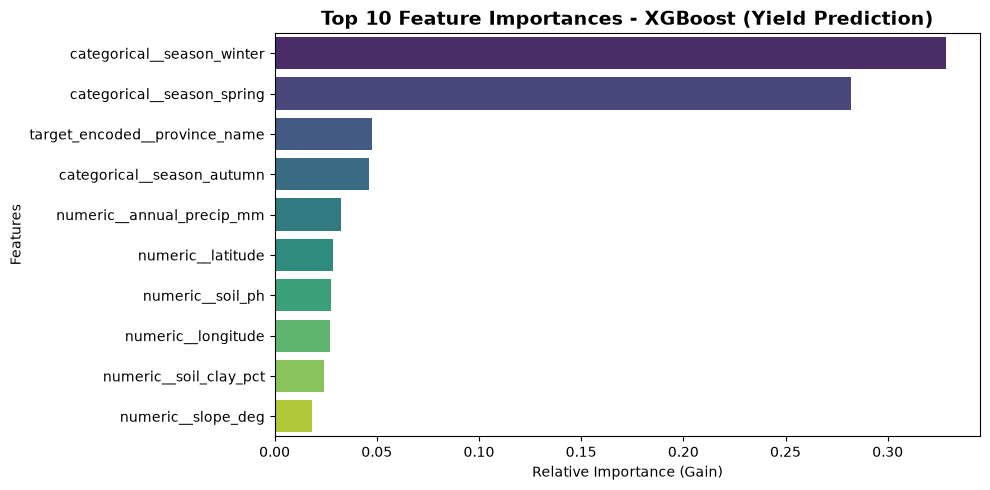

In [7]:
feature_names = final_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get XGBoost feature importances
importances = final_model.named_steps[
    "regressor"
].feature_importances_

# Build sorted importance table
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

display(importance_df)

# Plot Top Features Inline
plt.figure(figsize=(10, 5))
top_n = 10
sns.barplot(
    x='importance',
    y='feature',
    hue='feature',
    legend=False,
    data=importance_df.head(top_n),
    palette='viridis'
)
plt.title(f"Top {top_n} Feature Importances - XGBoost (Yield Prediction)", fontsize=14, fontweight='bold')
plt.xlabel("Relative Importance (Gain)", fontsize=10)
plt.ylabel("Features", fontsize=10)
plt.tight_layout()
plt.show()

## Find the train-val across Folds

In [8]:
# ============================================================
# 8. GROUP CROSS-VALIDATION
# ============================================================

gkf = GroupKFold(n_splits=5)

train_r2s = []
val_r2s = []
train_rmses = []
val_rmses = []

for fold, (train_idx, val_idx) in enumerate(
    gkf.split(X, y, groups=groups), start=1
):
    # Separate names so the chronological X_train / X_val above are not overwritten
    X_tr = X.iloc[train_idx].copy()
    X_va = X.iloc[val_idx].copy()

    y_tr = y.iloc[train_idx]
    y_va = y.iloc[val_idx]

    cv_model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("regressor", xgb.XGBRegressor(**best_params))
    ])

    # Fit preprocessing and model using training fold only
    cv_model.fit(X_tr, y_tr)

    train_preds = cv_model.predict(X_tr)
    val_preds = cv_model.predict(X_va)

    train_r2 = r2_score(y_tr, train_preds)
    val_r2 = r2_score(y_va, val_preds)

    train_rmse = rmse(y_tr, train_preds)
    val_rmse = rmse(y_va, val_preds)

    train_r2s.append(train_r2)
    val_r2s.append(val_r2)
    train_rmses.append(train_rmse)
    val_rmses.append(val_rmse)

    print(f"\nFold {fold}")
    print(f"Training R²:   {train_r2:.4f}")
    print(f"Validation R²: {val_r2:.4f}")
    print(f"Training RMSE: {train_rmse:.4f}")
    print(f"Validation RMSE: {val_rmse:.4f}")

# ============================================================
# 9. SUMMARY
# ============================================================

mean_train_r2 = np.mean(train_r2s)
mean_val_r2 = np.mean(val_r2s)

print("\n" + "=" * 45)
print("GROUP CROSS-VALIDATION RESULTS")
print("=" * 45)

print(f"Average Training R²:   {mean_train_r2:.4f}")
print(f"Average Validation R²: {mean_val_r2:.4f}")
print(f"Train-Val Gap:         {mean_train_r2 - mean_val_r2:.4f}")

print(f"Average Training RMSE:   {np.mean(train_rmses):.4f}")
print(f"Average Validation RMSE: {np.mean(val_rmses):.4f}")


Fold 1
Training R²:   0.9755
Validation R²: 0.8570
Training RMSE: 0.1813
Validation RMSE: 0.4314

Fold 2
Training R²:   0.9749
Validation R²: 0.8808
Training RMSE: 0.1835
Validation RMSE: 0.3932

Fold 3
Training R²:   0.9757
Validation R²: 0.8400
Training RMSE: 0.1816
Validation RMSE: 0.4462

Fold 4
Training R²:   0.9806
Validation R²: 0.8011
Training RMSE: 0.1604
Validation RMSE: 0.5185

Fold 5
Training R²:   0.9793
Validation R²: 0.7919
Training RMSE: 0.1642
Validation RMSE: 0.5520

GROUP CROSS-VALIDATION RESULTS
Average Training R²:   0.9772
Average Validation R²: 0.8341
Train-Val Gap:         0.1431
Average Training RMSE:   0.1742
Average Validation RMSE: 0.4683


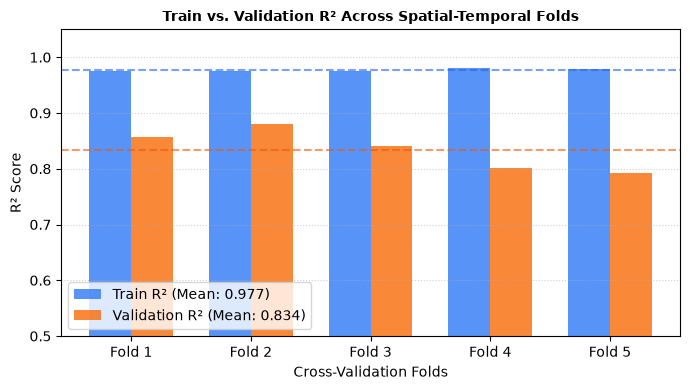

In [9]:
folds = [f"Fold {i+1}" for i in range(len(train_r2s))]
x = np.arange(len(folds))
width = 0.35

plt.figure(figsize=(7, 4))
plt.bar(x - width/2, train_r2s, width, label=f'Train R² (Mean: {np.mean(train_r2s):.3f})', color='#3b82f6', alpha=0.85)
plt.bar(x + width/2, val_r2s, width, label=f'Validation R² (Mean: {np.mean(val_r2s):.3f})', color='#f97316', alpha=0.85)

plt.axhline(np.mean(train_r2s), color='#2563eb', linestyle='--', alpha=0.6)
plt.axhline(np.mean(val_r2s), color='#ea580c', linestyle='--', alpha=0.6)

plt.xlabel('Cross-Validation Folds', fontsize=10)
plt.ylabel('R² Score', fontsize=10)
plt.title('Train vs. Validation R² Across Spatial-Temporal Folds', fontsize=10, fontweight='bold')
plt.xticks(x, folds)
plt.ylim(min(0.5, min(val_r2s) - 0.05), 1.05)
plt.legend(loc='lower left', frameon=True)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## Underfit vs. Overfit Diagnostics

How to read the charts below:
- **Underfit:** train and validation scores are both low and close together.
- **Overfit:** train score is high, validation score is clearly lower (large gap).
- **Good fit:** both scores are high with a small gap.

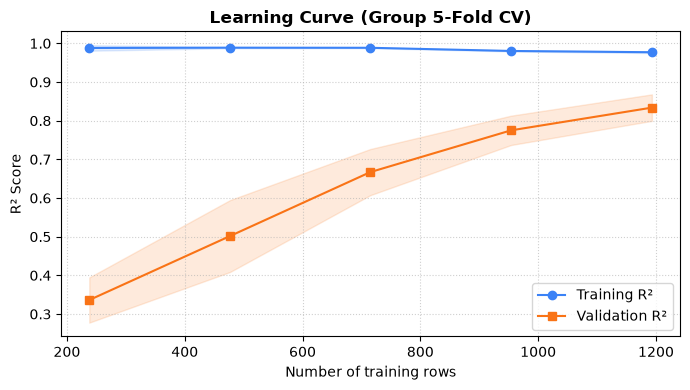

In [10]:
# ============================================================
# CHART 1: LEARNING CURVE (score vs. amount of training data)
# ============================================================

lc_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", xgb.XGBRegressor(**best_params))
])

train_sizes, lc_train, lc_val = learning_curve(
    lc_model, X, y,
    groups=groups,
    cv=GroupKFold(n_splits=5),
    train_sizes=np.linspace(0.2, 1.0, 5),
    scoring="r2",
    n_jobs=1
)

lc_train_mean, lc_train_std = lc_train.mean(axis=1), lc_train.std(axis=1)
lc_val_mean, lc_val_std = lc_val.mean(axis=1), lc_val.std(axis=1)

plt.figure(figsize=(7, 4))
plt.plot(train_sizes, lc_train_mean, marker="o", color="#3b82f6", label="Training R²")
plt.fill_between(train_sizes, lc_train_mean - lc_train_std, lc_train_mean + lc_train_std, color="#3b82f6", alpha=0.15)
plt.plot(train_sizes, lc_val_mean, marker="s", color="#f97316", label="Validation R²")
plt.fill_between(train_sizes, lc_val_mean - lc_val_std, lc_val_mean + lc_val_std, color="#f97316", alpha=0.15)

plt.xlabel("Number of training rows")
plt.ylabel("R² Score")
plt.title("Learning Curve (Group 5-Fold CV)", fontweight="bold")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

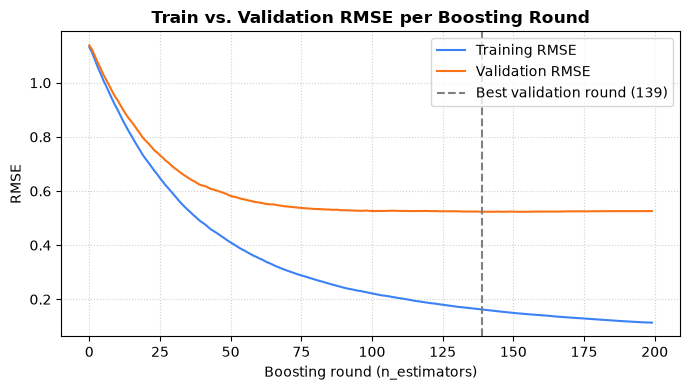

Total rounds: 200 | Best validation round: 139


In [11]:
# ============================================================
# CHART 2: TRAIN vs. VALIDATION ERROR PER BOOSTING ROUND
# ============================================================

curve_pre = clone(preprocessor)
X_train_t = curve_pre.fit_transform(X_train, y_train)
X_val_t = curve_pre.transform(X_val)

curve_reg = xgb.XGBRegressor(**{**best_params, "eval_metric": "rmse"})
curve_reg.fit(
    X_train_t, y_train,
    eval_set=[(X_train_t, y_train), (X_val_t, y_val)],
    verbose=False
)

evals = curve_reg.evals_result()
train_curve = evals["validation_0"]["rmse"]
val_curve = evals["validation_1"]["rmse"]
best_round = int(np.argmin(val_curve))

plt.figure(figsize=(7, 4))
plt.plot(train_curve, color="#3b82f6", label="Training RMSE")
plt.plot(val_curve, color="#f97316", label="Validation RMSE")
plt.axvline(best_round, color="gray", linestyle="--", label=f"Best validation round ({best_round})")

plt.xlabel("Boosting round (n_estimators)")
plt.ylabel("RMSE")
plt.title("Train vs. Validation RMSE per Boosting Round", fontweight="bold")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Total rounds: {len(val_curve)} | Best validation round: {best_round}")

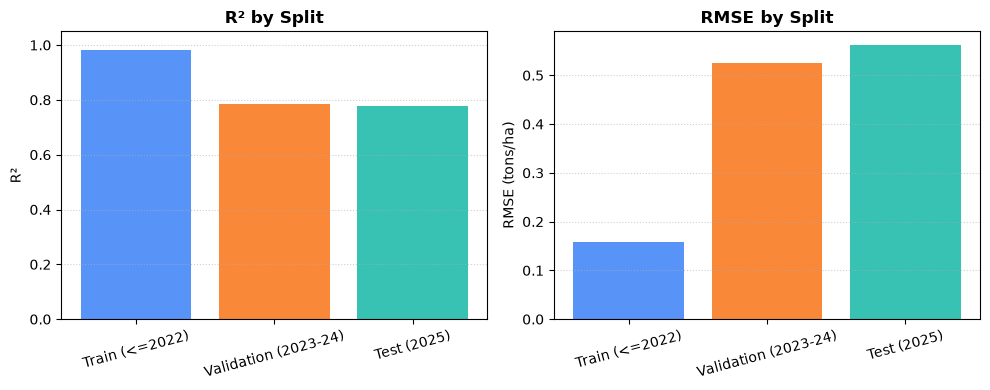

Train-Val R² gap:  0.1980
Train-Test R² gap: 0.2028


In [12]:
# ============================================================
# CHART 3: TRAIN vs. VALIDATION vs. TEST (chronological split)
# ============================================================

score_df = pd.DataFrame(split_scores).T

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
bar_colors = ["#3b82f6", "#f97316", "#14b8a6"]

axes[0].bar(score_df.index, score_df["R2"], color=bar_colors, alpha=0.85)
axes[0].set_title("R² by Split", fontweight="bold")
axes[0].set_ylabel("R²")
axes[0].set_ylim(min(0.0, score_df["R2"].min() - 0.05), 1.05)

axes[1].bar(score_df.index, score_df["RMSE"], color=bar_colors, alpha=0.85)
axes[1].set_title("RMSE by Split", fontweight="bold")
axes[1].set_ylabel("RMSE (tons/ha)")

for ax in axes:
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

print(f"Train-Val R² gap:  {score_df.loc['Train (<=2022)', 'R2'] - score_df.loc['Validation (2023-24)', 'R2']:.4f}")
print(f"Train-Test R² gap: {score_df.loc['Train (<=2022)', 'R2'] - score_df.loc['Test (2025)', 'R2']:.4f}")

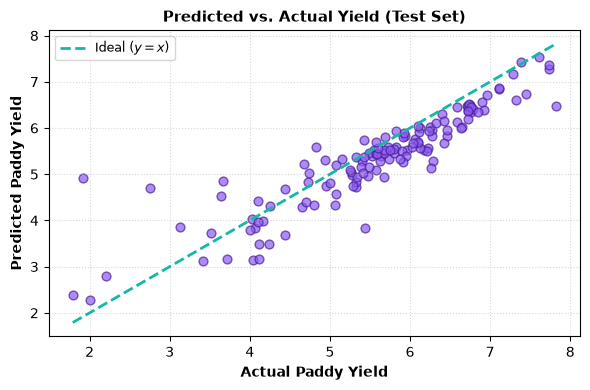

In [13]:
y_pred = holdout_model.predict(X_test)

plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred, alpha=0.7, color='#8b5cf6', edgecolors='#4c1d95', s=40)

# Draw the ideal 1:1 line in Teal to match the theme
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='#14b8a6', linestyle='--', lw=2, label='Ideal ($y = x$)')

plt.xlabel('Actual Paddy Yield', fontsize=10, fontweight='bold')
plt.ylabel('Predicted Paddy Yield', fontsize=10, fontweight='bold')
plt.title('Predicted vs. Actual Yield (Test Set)', fontsize=11, fontweight='bold')
plt.legend(frameon=True, fontsize=9)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig("scatterplot.png", dpi=300, bbox_inches="tight")
plt.show()

## SHAP

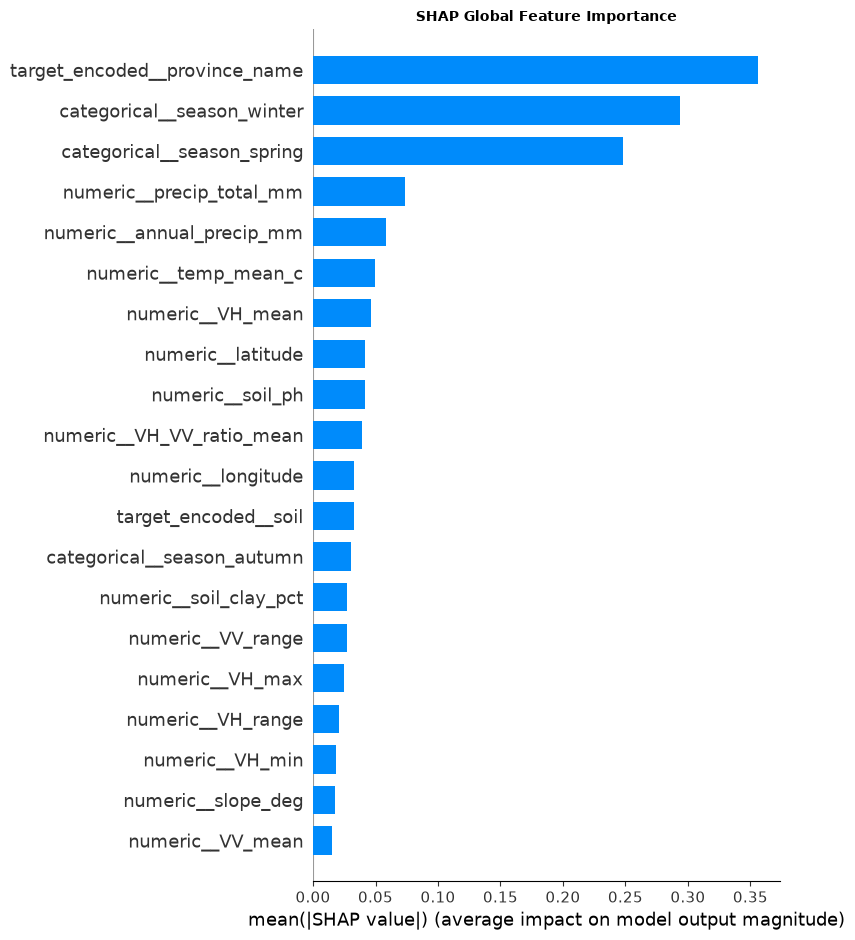

In [14]:
import shap

# Use the fitted preprocessor of the final model so SHAP sees the same
# numeric features the model was trained on (no object/string columns).
final_pre = final_model.named_steps["preprocessor"]
final_reg = final_model.named_steps["regressor"]

X_shap_arr = final_pre.transform(X)
if hasattr(X_shap_arr, "toarray"):  # sparse -> dense
    X_shap_arr = X_shap_arr.toarray()

X_shap = pd.DataFrame(
    X_shap_arr.astype("float64"),
    columns=final_pre.get_feature_names_out(),
    index=X.index
)

# Initialize the SHAP TreeExplainer and calculate values
explainer = shap.TreeExplainer(final_reg)
shap_values = explainer(X_shap)

# Plot 1: Global Feature Importance Bar Plot
plt.figure(figsize=(8, 6))
shap.summary_plot(shap_values, X_shap, plot_type="bar", show=False)
plt.title("SHAP Global Feature Importance", fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

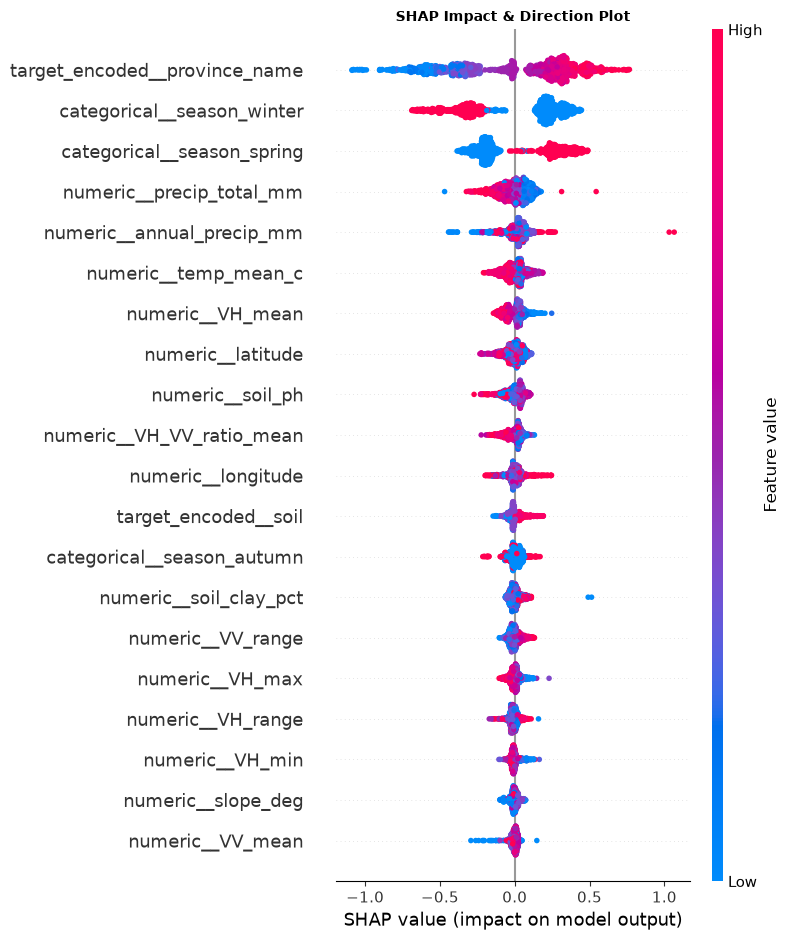

In [15]:
# Plot 2: SHAP Beeswarm Plot (Magnitude and Direction)
plt.figure(figsize=(8, 6))
shap.summary_plot(shap_values, X_shap, show=False)
plt.title("SHAP Impact & Direction Plot", fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig("beeswarm_features.png", dpi=300, bbox_inches="tight")
plt.show()

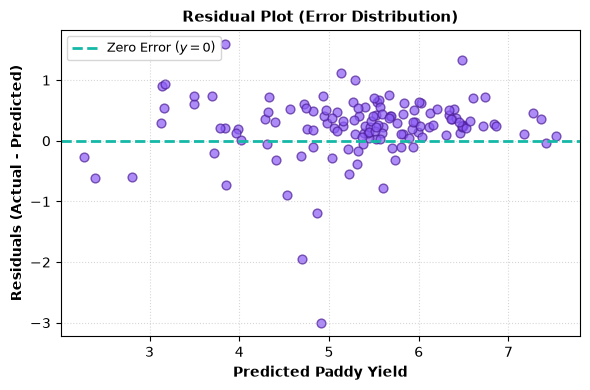

In [16]:
y_pred = holdout_model.predict(X_test)
residuals = y_test - y_pred

plt.figure(figsize=(6, 4))
# Scatter plot of residuals vs. predicted values (styled in Purple)
plt.scatter(y_pred, residuals, alpha=0.7, color='#8b5cf6', edgecolors='#4c1d95', s=40)

# Draw a horizontal zero-error reference line in Teal
plt.axhline(0, color='#14b8a6', linestyle='--', lw=2, label='Zero Error ($y = 0$)')

plt.xlabel('Predicted Paddy Yield', fontsize=10, fontweight='bold')
plt.ylabel('Residuals (Actual - Predicted)', fontsize=10, fontweight='bold')
plt.title('Residual Plot (Error Distribution)', fontsize=11, fontweight='bold')
plt.legend(frameon=True, fontsize=9)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig("residuals.png", dpi=300, bbox_inches="tight")
plt.show()

Training XGBoost with learning_rate=0.005
Training XGBoost with learning_rate=0.01
Training XGBoost with learning_rate=0.02
Training XGBoost with learning_rate=0.03
Training XGBoost with learning_rate=0.05
Training XGBoost with learning_rate=0.1

LEARNING RATE RESULTS


,learning_rate,train_R2,val_R2,train_RMSE,val_RMSE
0,0.005,0.7550,0.6374,0.5699,0.6804
1,0.010,0.9122,0.7578,0.3412,0.5561
2,0.020,0.9694,0.7838,0.2015,0.5254
3,0.030,0.9813,0.7832,0.1576,0.5261
4,0.050,0.9896,0.7807,0.1176,0.5292
5,0.100,0.9924,0.7740,0.1002,0.5372


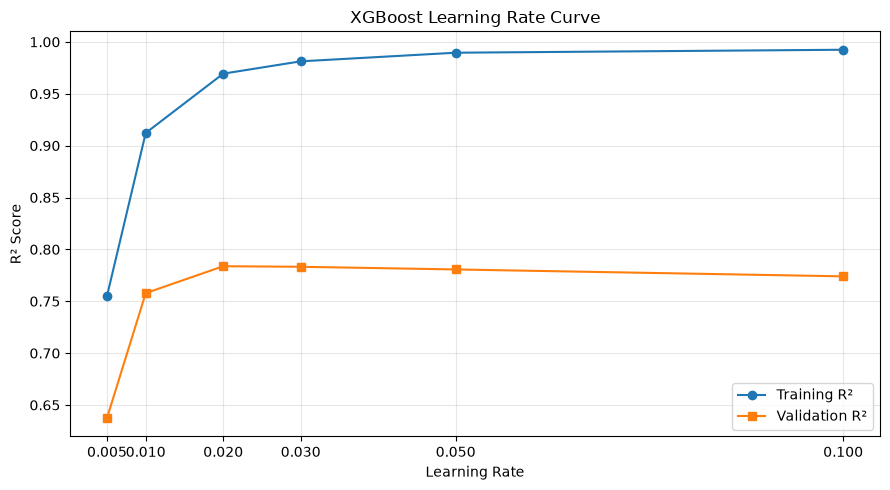

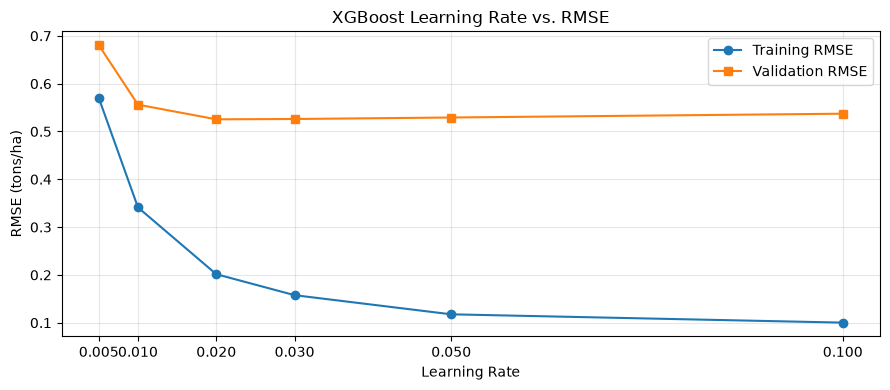


Best learning rate based on validation RMSE:
learning_rate    0.0200
train_R2         0.9694
val_R2           0.7838
train_RMSE       0.2015
val_RMSE         0.5254
Name: 2, dtype: float64


In [17]:
# ============================================================
# 1. DEFINE LEARNING RATES TO TEST
# ============================================================

learning_rates = [0.005, 0.01, 0.02, 0.03, 0.05, 0.1]

results = []

# ============================================================
# 2. TRAIN AND EVALUATE EACH LEARNING RATE
# ============================================================

for lr in learning_rates:
    print(f"Training XGBoost with learning_rate={lr}")

    lr_model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("regressor", xgb.XGBRegressor(
            learning_rate=lr,
            max_depth=7,
            n_estimators=200,
            colsample_bytree=0.6,
            subsample=0.8,
            random_state=42,
            n_jobs=-1,
            objective="reg:squarederror",
            eval_metric="rmse"
        ))
    ])

    lr_model.fit(X_train, y_train)

    # Training predictions
    train_pred = lr_model.predict(X_train)

    # Validation predictions
    val_pred = lr_model.predict(X_val)

    results.append({
        "learning_rate": lr,
        "train_R2": r2_score(y_train, train_pred),
        "val_R2": r2_score(y_val, val_pred),
        "train_RMSE": rmse(y_train, train_pred),
        "val_RMSE": rmse(y_val, val_pred)
    })

# ============================================================
# 3. DISPLAY RESULTS
# ============================================================

results_df = pd.DataFrame(results)

print("\nLEARNING RATE RESULTS")
display(results_df.round(4))

# ============================================================
# 4. PLOT R² LEARNING RATE CURVE
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    results_df["learning_rate"],
    results_df["train_R2"],
    marker="o",
    label="Training R²"
)

plt.plot(
    results_df["learning_rate"],
    results_df["val_R2"],
    marker="s",
    label="Validation R²"
)

plt.xlabel("Learning Rate")
plt.ylabel("R² Score")
plt.title("XGBoost Learning Rate Curve")
plt.xticks(learning_rates)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 5. PLOT RMSE LEARNING RATE CURVE
# ============================================================

plt.figure(figsize=(9, 4))

plt.plot(
    results_df["learning_rate"],
    results_df["train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    results_df["learning_rate"],
    results_df["val_RMSE"],
    marker="s",
    label="Validation RMSE"
)

plt.xlabel("Learning Rate")
plt.ylabel("RMSE (tons/ha)")
plt.title("XGBoost Learning Rate vs. RMSE")
plt.xticks(learning_rates)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 6. IDENTIFY BEST LEARNING RATE
# ============================================================

best_row = results_df.loc[results_df["val_RMSE"].idxmin()]

print("\nBest learning rate based on validation RMSE:")
print(best_row.round(4))

## GridSearchCV

The search uses only years <= 2024 (train + validation). The 2025 test year is never used to pick parameters.
Grouped 5-fold CV keeps the same group logic as the rest of the notebook. The grid includes your current parameters, so they act as the baseline.

In [18]:
# ============================================================
# GRIDSEARCHCV (development years only: <= 2024)
# ============================================================
from sklearn.model_selection import GridSearchCV

dev_mask = train_mask | val_mask
X_dev = X.loc[dev_mask]
y_dev = y.loc[dev_mask]
groups_dev = groups.loc[dev_mask]

# Seed the target encoder so every candidate is scored on the same encoding
# (without a seed its internal CV shuffle adds ~0.03 R² of noise between runs)
grid_pre = clone(preprocessor)
try:
    grid_pre.set_params(target_encoded__encoder__random_state=42)
except ValueError:
    pass

# Parameters to search (current values: lr 0.03, n_estimators 200, depth 7, colsample 0.6, min_child_weight default 1)
param_grid_raw = {
    "learning_rate": [0.03, 0.05],
    "n_estimators": [100, 200],
    "max_depth": [4, 5, 7],
    "min_child_weight": [1, 5],
    "colsample_bytree": [0.6, 0.8],
}
param_grid = {f"regressor__{k}": v for k, v in param_grid_raw.items()}

# Everything not in the grid stays fixed at the current values (subsample, random_state, n_jobs)
fixed_params = {k: v for k, v in best_params.items() if k not in param_grid_raw}

grid_pipe = Pipeline([
    ("preprocessor", grid_pre),
    ("regressor", xgb.XGBRegressor(**fixed_params))
])

grid = GridSearchCV(
    estimator=grid_pipe,
    param_grid=param_grid,
    scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"},
    refit="rmse",
    cv=GroupKFold(n_splits=5),
    return_train_score=True,
    n_jobs=1,       # XGBoost already uses all cores
    verbose=1
)

grid.fit(X_dev, y_dev, groups=groups_dev)

print("Best parameters:", grid.best_params_)
print(f"Best CV validation RMSE: {-grid.best_score_:.4f}")

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best parameters: {'regressor__colsample_bytree': 0.8, 'regressor__learning_rate': 0.05, 'regressor__max_depth': 7, 'regressor__min_child_weight': 5, 'regressor__n_estimators': 200}
Best CV validation RMSE: 0.4644


,param_regressor__colsample_bytree,param_regressor__learning_rate,param_regressor__max_depth,param_regressor__min_child_weight,param_regressor__n_estimators,train_RMSE,val_RMSE,train_R2,val_R2,R2_gap
0,0.8,0.05,7,5,200,0.1691,0.4644,0.9784,0.8339,0.1445
1,0.8,0.05,7,5,100,0.2310,0.4648,0.9597,0.8339,0.1258
2,0.8,0.03,7,5,200,0.2130,0.4666,0.9657,0.8323,0.1334
3,0.6,0.05,7,5,100,0.2295,0.4667,0.9601,0.8327,0.1274
4,0.6,0.03,7,5,200,0.2109,0.4671,0.9663,0.8323,0.1340
5,0.6,0.05,7,5,200,0.1652,0.4672,0.9793,0.8319,0.1475
6,0.8,0.03,7,5,100,0.2868,0.4683,0.9378,0.8319,0.1059
7,0.6,0.05,7,1,200,0.1252,0.4696,0.9881,0.8307,0.1574
8,0.8,0.03,7,1,200,0.1637,0.4702,0.9797,0.8306,0.1491
9,0.6,0.03,7,1,200,0.1615,0.4711,0.9803,0.8299,0.1504



Current parameters in the grid:


,param_regressor__colsample_bytree,param_regressor__learning_rate,param_regressor__max_depth,param_regressor__min_child_weight,param_regressor__n_estimators,train_RMSE,val_RMSE,train_R2,val_R2,R2_gap
9,0.6,0.03,7,1,200,0.1615,0.4711,0.9803,0.8299,0.1504


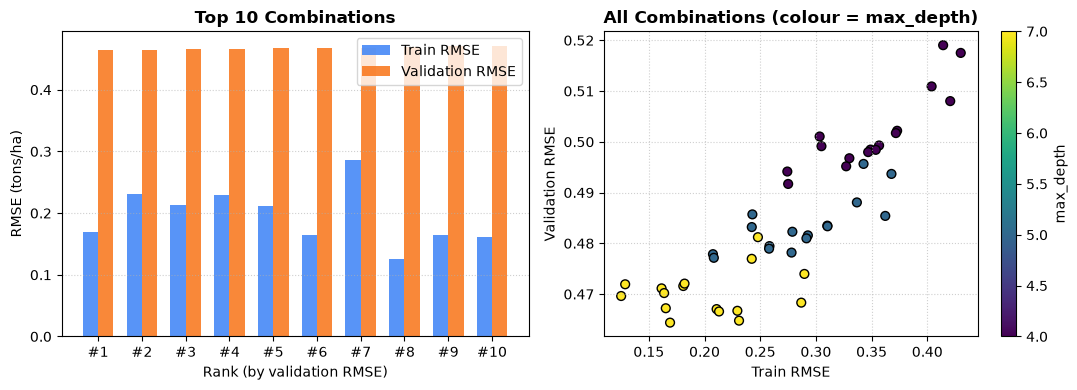

In [19]:
# ============================================================
# GRIDSEARCH RESULTS
# ============================================================
cv_res = pd.DataFrame(grid.cv_results_)

cv_res["train_RMSE"] = -cv_res["mean_train_rmse"]
cv_res["val_RMSE"] = -cv_res["mean_test_rmse"]
cv_res["train_R2"] = cv_res["mean_train_r2"]
cv_res["val_R2"] = cv_res["mean_test_r2"]
cv_res["R2_gap"] = cv_res["train_R2"] - cv_res["val_R2"]

param_cols = [c for c in cv_res.columns if c.startswith("param_")]
metric_cols = ["train_RMSE", "val_RMSE", "train_R2", "val_R2", "R2_gap"]

top10 = cv_res.sort_values("val_RMSE").head(10)[param_cols + metric_cols].reset_index(drop=True)
display(top10.round(4))

# Row for the current parameters (same grid point)
cur = cv_res[
    (cv_res["param_regressor__learning_rate"] == best_params["learning_rate"]) &
    (cv_res["param_regressor__n_estimators"] == best_params["n_estimators"]) &
    (cv_res["param_regressor__max_depth"] == best_params["max_depth"]) &
    (cv_res["param_regressor__min_child_weight"] == 1) &
    (cv_res["param_regressor__colsample_bytree"] == best_params["colsample_bytree"])
]
print("\nCurrent parameters in the grid:")
display(cur[param_cols + metric_cols].round(4))

# ---- Charts: top-10 train vs val RMSE, and train vs val RMSE for every combination ----
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

x = np.arange(len(top10))
w = 0.35
axes[0].bar(x - w/2, top10["train_RMSE"], w, color="#3b82f6", alpha=0.85, label="Train RMSE")
axes[0].bar(x + w/2, top10["val_RMSE"], w, color="#f97316", alpha=0.85, label="Validation RMSE")
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"#{i+1}" for i in x])
axes[0].set_xlabel("Rank (by validation RMSE)")
axes[0].set_ylabel("RMSE (tons/ha)")
axes[0].set_title("Top 10 Combinations", fontweight="bold")
axes[0].legend()
axes[0].grid(axis="y", linestyle=":", alpha=0.6)

sc = axes[1].scatter(
    cv_res["train_RMSE"], cv_res["val_RMSE"],
    c=cv_res["param_regressor__max_depth"].astype(int), cmap="viridis", s=40, edgecolors="k"
)
axes[1].set_xlabel("Train RMSE")
axes[1].set_ylabel("Validation RMSE")
axes[1].set_title("All Combinations (colour = max_depth)", fontweight="bold")
axes[1].grid(True, linestyle=":", alpha=0.6)
plt.colorbar(sc, ax=axes[1], label="max_depth")

plt.tight_layout()
plt.show()

In [20]:
# ============================================================
# CURRENT vs. GRIDSEARCH-BEST ON THE UNTOUCHED 2025 TEST SET
# Both models are trained on years <= 2024.
# ============================================================
gs_best_params = {k.replace("regressor__", ""): v for k, v in grid.best_params_.items()}

candidates = {
    "Current params": dict(best_params),
    "GridSearch best": {**best_params, **gs_best_params},
}

compare_rows = {}
for name, params in candidates.items():
    m = Pipeline([
        ("preprocessor", clone(grid_pre)),
        ("regressor", xgb.XGBRegressor(**params))
    ])
    m.fit(X_dev, y_dev)

    dev_pred = m.predict(X_dev)
    test_pred = m.predict(X_test)

    compare_rows[name] = {
        "Train R2": r2_score(y_dev, dev_pred),
        "Test R2": r2_score(y_test, test_pred),
        "Train RMSE": rmse(y_dev, dev_pred),
        "Test RMSE": rmse(y_test, test_pred),
    }

compare_df = pd.DataFrame(compare_rows).T
compare_df["R2 gap"] = compare_df["Train R2"] - compare_df["Test R2"]
display(compare_df.round(4))

print("\nGridSearch best parameters:")
display(candidates["GridSearch best"])

,Train R2,Test R2,Train RMSE,Test RMSE,R2 gap
Current params,0.9750,0.8405,0.1820,0.4769,0.1345
GridSearch best,0.9767,0.8480,0.1757,0.4656,0.1287



GridSearch best parameters:


{'learning_rate': 0.05,
 'max_depth': 7,
 'n_estimators': 200,
 'colsample_bytree': 0.8,
 'subsample': 0.8,
 'random_state': 42,
 'n_jobs': -1,
 'min_child_weight': 5}

## GridSearchCV - Round 2 with reg lambda

In [22]:
base_params = {**best_params, **gs_best_params}   # round-1 winner

param_grid_raw_2 = {
    "reg_lambda": [1, 2, 5, 10, 20],   # 1 = XGBoost default
}
param_grid_2 = {f"regressor__{k}": v for k, v in param_grid_raw_2.items()}
fixed_params_2 = {k: v for k, v in base_params.items() if k not in param_grid_raw_2}

grid_2 = GridSearchCV(
    estimator=Pipeline([
        ("preprocessor", clone(grid_pre)),
        ("regressor", xgb.XGBRegressor(**fixed_params_2))
    ]),
    param_grid=param_grid_2,
    scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"},
    refit="rmse",
    cv=GroupKFold(n_splits=5),
    return_train_score=True,
    n_jobs=1,
    verbose=1
)
grid_2.fit(X_dev, y_dev, groups=groups_dev)

# ---------- results ----------
res2 = pd.DataFrame(grid_2.cv_results_)
res2["reg_lambda"] = res2["param_regressor__reg_lambda"].astype(float)
res2["train_RMSE"] = -res2["mean_train_rmse"]
res2["val_RMSE"] = -res2["mean_test_rmse"]
res2["train_R2"] = res2["mean_train_r2"]
res2["val_R2"] = res2["mean_test_r2"]
res2["R2_gap"] = res2["train_R2"] - res2["val_R2"]
res2 = res2.sort_values("reg_lambda")

display(res2[["reg_lambda", "train_RMSE", "val_RMSE", "train_R2", "val_R2", "R2_gap"]].round(4))

Fitting 5 folds for each of 5 candidates, totalling 25 fits


,reg_lambda,train_RMSE,val_RMSE,train_R2,val_R2,R2_gap
0,1.0,0.1691,0.4644,0.9784,0.8339,0.1445
1,2.0,0.1723,0.4637,0.9775,0.8342,0.1434
2,5.0,0.1936,0.4664,0.9716,0.8323,0.1393
3,10.0,0.2144,0.4687,0.9652,0.8304,0.1348
4,20.0,0.2433,0.4769,0.9552,0.8248,0.1303


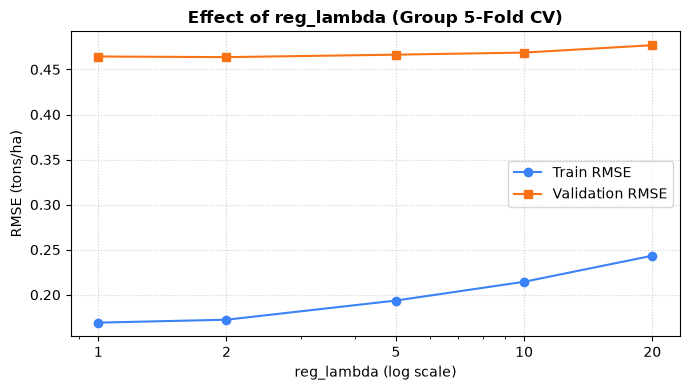

CV val RMSE with reg_lambda=1 (default): 0.4644
CV val RMSE with best reg_lambda=2: 0.4637
Improvement: 0.0007 (needs >= 0.005)

-> reg_lambda did NOT improve enough. Keeping the round-1 parameters.


,Train R2,Test R2,Train RMSE,Test RMSE,R2 gap
Current params,0.9750,0.8405,0.1820,0.4769,0.1345
Round-1 best,0.9767,0.8480,0.1757,0.4656,0.1287
Final (round 2),0.9767,0.8480,0.1757,0.4656,0.1287



Final parameters:


{'learning_rate': 0.05,
 'max_depth': 7,
 'n_estimators': 200,
 'colsample_bytree': 0.8,
 'subsample': 0.8,
 'random_state': 42,
 'n_jobs': -1,
 'min_child_weight': 5}

In [23]:
# ---------- chart: reg_lambda vs train / validation RMSE ----------
plt.figure(figsize=(7, 4))
plt.plot(res2["reg_lambda"], res2["train_RMSE"], marker="o", color="#3b82f6", label="Train RMSE")
plt.plot(res2["reg_lambda"], res2["val_RMSE"], marker="s", color="#f97316", label="Validation RMSE")
plt.xscale("log")
plt.xticks(res2["reg_lambda"], res2["reg_lambda"].astype(int))
plt.xlabel("reg_lambda (log scale)")
plt.ylabel("RMSE (tons/ha)")
plt.title("Effect of reg_lambda (Group 5-Fold CV)", fontweight="bold")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# ---------- did reg_lambda improve the CV score? ----------
baseline_val_rmse = res2.loc[res2["reg_lambda"] == 1, "val_RMSE"].iloc[0]
new_val_rmse = -grid_2.best_score_
min_gain = 0.005   # require at least ~0.005 t/ha lower CV RMSE to count as an improvement

improved = (baseline_val_rmse - new_val_rmse) >= min_gain
best_lambda = grid_2.best_params_["regressor__reg_lambda"]

print(f"CV val RMSE with reg_lambda=1 (default): {baseline_val_rmse:.4f}")
print(f"CV val RMSE with best reg_lambda={best_lambda}: {new_val_rmse:.4f}")
print(f"Improvement: {baseline_val_rmse - new_val_rmse:.4f} (needs >= {min_gain})")

if improved:
    final_params = {**base_params, "reg_lambda": best_lambda}
    print(f"\n-> reg_lambda IMPROVED the model. Using reg_lambda={best_lambda}.")
else:
    final_params = dict(base_params)
    print("\n-> reg_lambda did NOT improve enough. Keeping the round-1 parameters.")

# ---------- check on the untouched 2025 test set (information only) ----------
candidates_2 = {
    "Current params": dict(best_params),
    "Round-1 best": dict(base_params),
    "Final (round 2)": dict(final_params),
}

rows = {}
for name, params in candidates_2.items():
    m = Pipeline([
        ("preprocessor", clone(grid_pre)),
        ("regressor", xgb.XGBRegressor(**params))
    ])
    m.fit(X_dev, y_dev)
    dev_pred = m.predict(X_dev)
    test_pred = m.predict(X_test)
    rows[name] = {
        "Train R2": r2_score(y_dev, dev_pred),
        "Test R2": r2_score(y_test, test_pred),
        "Train RMSE": rmse(y_dev, dev_pred),
        "Test RMSE": rmse(y_test, test_pred),
    }

compare_2 = pd.DataFrame(rows).T
compare_2["R2 gap"] = compare_2["Train R2"] - compare_2["Test R2"]
display(compare_2.round(4))

print("\nFinal parameters:")
display(final_params)